# Downloading waveforms for the 2025-10-25 Vandenberg rocket launch with ObsPy and FDSN web services

This notebook downloads
20 minutes (14:20–14:40 UTC) of continuous **CI HHZ** data for every station within 200 km of
Vandenberg launch pad **SLC-4E**, covering the Falcon 9 Starlink 11-12 launch on 2025-10-25, and
plots it as a record section sorted by distance from the pad.

Sound from a rocket launch travels through the air and shakes the ground as it passes, so
seismometers record it. The Southern California Seismic Network (SCSN) catalogued this one as
sonic event `41319720`.

The workflow uses two FDSN web services at SCEDC:

1. The **station** service to find out which channels exist: which CI HHZ channels were
   running during the window and lie within 200 km of the pad.
2. The **dataselect** service to download the actual ground-motion time series for exactly
   those channels.

FDSN (International Federation of Digital Seismograph Networks) defines standard
web-service APIs that most data centers implement (SCEDC, EarthScope/IRIS, NCEDC, GEOFON, ...):

| Service | Returns |
|---|---|
| `fdsnws/event/1/` | earthquake catalogs: QuakeML (XML), GeoJSON, text (not used here) |
| `fdsnws/station/1/` | station metadata: StationXML, text |
| `fdsnws/dataselect/1/` | waveform data: miniSEED |

Because the APIs are the same everywhere, ObsPy's FDSN `Client` can talk to any of
these data centers with identical code. Only the name changes.

Each service is a plain URL with query parameters, so you can try it in a browser or with
`curl` first. The station query in Step 1 is equivalent to:

```
https://service.scedc.caltech.edu/fdsnws/station/1/query?net=CI&cha=HHZ
    &starttime=2025-10-25T14:20:00&endtime=2025-10-25T14:40:00
    &lat=34.632&lon=-120.611&maxradius=1.8&level=channel&format=text
```

Key ObsPy objects used below:

```
Inventory -> Network -> Station -> Channel   (station metadata)
Stream    -> Trace -> .data (numpy array), .stats (metadata)
UTCDateTime        a timestamp you can add or subtract seconds from
```

## Imports

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from obspy import UTCDateTime
# Client is ObsPy's generic FDSN web-service client. Client("SCEDC") looks up
# the SCEDC base URL (https://service.scedc.caltech.edu) from ObsPy's built-in
# list; you can also pass a full URL for data centers not in that list.
from obspy.clients.fdsn import Client
# gps2dist_azimuth returns the distance (in meters) and azimuths between two
# points on the WGS84 ellipsoid.
from obspy.geodetics import gps2dist_azimuth

%matplotlib inline

## Parameters

Change these and re-run the cells below.

* FDSN uses **decimal degrees**, with longitudes west of Greenwich negative.
* FDSN times are always **UTC**, in ISO 8601 form (`YYYY-MM-DDThh:mm:ss`). `UTCDateTime` parses that form,
  and adding or subtracting a number shifts it by that many seconds.
* Radius searches (`minradius`/`maxradius`) are in **degrees of arc**, not km. 1° ≈ 111.19 km, so 1.8° ≈ 200 km.

Downloaded files go in `data/`: the channel list in `data/hhz.txt` and one miniSEED file per
channel in `data/wf/`.

In [2]:
PAD = (34.632, -120.611)          # SLC-4E (latitude, longitude)
T0 = UTCDateTime("2025-10-25T14:20:00")
T1 = T0 + 1200                    # 20 minutes later
RADIUS_DEG = 1.8                  # ~200 km

DATA = Path("data")
(DATA / "wf").mkdir(parents=True, exist_ok=True)

## Connect to a data center

`"SCEDC"` is a shortcut ObsPy maps to `https://service.scedc.caltech.edu`. Other shortcuts include `"IRIS"`
(EarthScope), `"NCEDC"` and `"GEOFON"`; you can also pass a full base URL.

Create the client once and reuse it. Creating a Client contacts the server and reads each
service's description (WADL) to discover which services and parameters it supports, so
don't create one per request.

In [3]:
client = Client("SCEDC")
print(client)

FDSN Webservice Client (base url: http://service.scedc.caltech.edu)
Available Services: 'dataselect' (v1.1.0), 'event' (v1.1.1), 'station' (v1.1.0), 'available_event_catalogs', 'available_event_contributors'

Use e.g. client.help('dataselect') for the
parameter description of the individual services
or client.help() for parameter description of
all webservices.


## Step 1: find the channels with the station service

Filters used:

* `network="CI"`: the Southern California Seismic Network.
* `channel="HHZ"`: SEED channel code (H = high sample rate, 100 Hz here; H = high-gain
  seismometer; Z = vertical). Wildcards are allowed (`"HH?"` = all three components, `"BH*,HH*"`, ...).
* `starttime`/`endtime`: keep only channel epochs that were running during our window, so stations closed years ago are left out.
* `latitude`/`longitude`/`maxradius`: a circular search around the pad. Use `minlatitude`…`maxlongitude` for a box instead.
* `level="channel"`: how much detail to return: `"network"`, `"station"`, `"channel"`, or `"response"`. `"response"`
  adds the full instrument response, which `Stream.remove_response()` needs, but it is larger and slower to download.

The result is an ObsPy `Inventory`: a tree of Network -> Station -> Channel objects.

In [4]:
inv = client.get_stations(network="CI", channel="HHZ", starttime=T0, endtime=T1,
                          latitude=PAD[0], longitude=PAD[1], maxradius=RADIUS_DEG,
                          level="channel")
print(inv)

Inventory created at 2026-11-02T05:35:09.000000Z
	Created by: SCEDC WEB SERVICE: fdsnws-station | version: 1.1
		    http://service.scedc.caltech.edu/fdsnws/station/1/query?net=CI&cha=...
	Sending institution: SCEDC (SCEDC)
	Contains:
		Networks (1):
			CI
		Stations (77):
			CI.ABL (Mount Abel)
			CI.ARV (Arvin)
			CI.BAI (Bailey)
			CI.BAK (Calstate Bakersfield)
			CI.BCH (Branch Mtn)
			CI.BCW (Bitter Creek Wildlife)
			CI.BLC (Black Canyon)
			CI.BTP (Burnt Peak)
			CI.BUE (Buellton - FS #31)
			CI.CDM (Casitas Dam)
			CI.CHI (Channel Island)
			CI.CHK (Camp Hess Kramer)
			CI.CHR (Ventucopa)
			CI.CLO (Camarillo)
			CI.CRG (Crocker Grade)
			CI.CRY (Choke Cherry)
			CI.CVW (Castaic Valley West)
			CI.EOC (Emergency Office Center)
			CI.FDR (5 Dogs Range)
			CI.FIG (Figueroa Mountain)
			CI.FMO (Fillmore)
			CI.GATR (GATR Compound)
			CI.GDF (Good Enough Ridge, Los Padres NF)
			CI.GFS (Santa Barbara County Fire Station #18)
			CI.HDH (High Desert Hunt Club - Tejon Ranch)
			CI.HHL

Save the channel list in FDSN **text format**: one pipe-delimited line per channel, with coordinates, elevation,
depth, orientation and sample rate. Use `format="STATIONXML"` instead to keep the full metadata.

In [5]:
inv.write(str(DATA / "hhz.txt"), format="STATIONTXT", level="channel")
print(open(DATA / "hhz.txt").read()[:600])

#Network|Station|Location|Channel|Latitude|Longitude|Elevation|Depth|Azimuth|Dip|SensorDescription|Scale|ScaleFreq|ScaleUnits|SampleRate|StartTime|EndTime
CI|ABL||HHZ|34.84843|-119.224965|1974.2|0.8|0.0|-90.0|OMNISENSOR,Velocity Sensor,KINEMETRICS|629601000.0|1.0|M/S|100.0|2024-07-31T21:48:18|3000-01-01T00:00:00
CI|ARV||HHZ|35.1269|-118.83009|258.0|1.0|0.0|-90.0|STRECKEISEN STS-2.5 S/N:120321 Velocity Sensor|629536560.4363471|1.0|m/s|100.0|2022-09-29T19:00:00|2026-03-19T20:00:21
CI|BAI||HHZ|34.77695|-118.77335|1035.0|0.0|0.0|-90.0|MBB-2,Velocity Sensor,EQMET|314801000.0|1.0|M/S|100.0|2024-07-2


## Step 2: download the waveforms with the dataselect service

Every channel is identified by four codes, **NSLC**: Network.Station.Location.Channel (e.g. `CI.SBC..HHZ`).
We walk the `Inventory` tree to collect them. FDSN services spell an empty location code as `"--"`,
because a blank field can't be sent in the space-separated bulk format.

Note: we list channel names explicitly here, because SCEDC bulk requests return nothing for `?` wildcards.

A bulk request is a list of `(network, station, location, channel, starttime, endtime)`. ObsPy sends it as a
single HTTP POST to `fdsnws/dataselect/1/query`. For many channels at once, `Client.get_waveforms_bulk()` is
much faster, and easier on the server, than a loop of single `client.get_waveforms(...)` requests. The request
body looks like this:

In [6]:
nslc = sorted({(n.code, s.code, c.location_code or "--", c.code)
               for n in inv for s in n for c in s})
bulk = [code + (T0, T1) for code in nslc]
print(f"requesting {len(bulk)} channels; first lines of the POST body:")
for b in bulk[:3]:
    print(" ".join(b[:4]), b[4].strftime("%Y-%m-%dT%H:%M:%S"), b[5].strftime("%Y-%m-%dT%H:%M:%S"))

requesting 77 channels; first lines of the POST body:
CI ABL -- HHZ 2025-10-25T14:20:00 2025-10-25T14:40:00
CI ARV -- HHZ 2025-10-25T14:20:00 2025-10-25T14:40:00
CI BAI -- HHZ 2025-10-25T14:20:00 2025-10-25T14:40:00


The server returns **miniSEED**, the standard binary format for seismic time series. The result is an
ObsPy `Stream`: a list of `Trace` objects, one per contiguous chunk of data.

* Channels with no data in the window are simply left out of the reply; this is not an error.
  The FDSN services answer "nothing matched at all" with HTTP 204 (No Content), which ObsPy
  turns into an `FDSNNoDataException` rather than returning an empty Stream.
* Add `attach_response=True` if you plan to remove the instrument response later with
  `st.remove_response()`.

In [7]:
st = client.get_waveforms_bulk(bulk)
print(st.__str__(extended=False))

76 Trace(s) in Stream:

CI.ABL..HHZ | 2025-10-25T14:20:00.000400Z - 2025-10-25T14:40:00.000400Z | 100.0 Hz, 120001 samples
...
(74 other traces)
...
CI.YEG2..HHZ | 2025-10-25T14:20:00.003100Z - 2025-10-25T14:40:00.003100Z | 100.0 Hz, 120001 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


## Step 3: save one file per channel

A gap in the data (telemetry dropout, etc.) makes the server return several Traces for one channel.
`merge(method=1)` joins them into one Trace per channel; where traces overlap it keeps the later one's
samples, and any remaining gaps become masked (`numpy.ma`) values.

Then we save one miniSEED file per channel, named by its trace id, so later scripts can read the data
without asking the server again. miniSEED cannot store masked arrays, so `split()` turns each Trace back
into gap-free pieces before writing. A gap stays a gap in the file.

In [8]:
st.merge(method=1)
for tr in st:
    tr.split().write(str(DATA / "wf" / f"{tr.id}.mseed"), format="MSEED")
size_mb = sum(f.stat().st_size for f in (DATA / "wf").glob("*.mseed")) / 1e6
print(f"saved {len(st)} channels ({size_mb:.1f} MB) to {DATA / 'wf'}")

# A station can be in the metadata and still have no data (outages,
# telemetry dropouts, not yet archived).
missing = sorted({b[1] for b in bulk} - {tr.stats.station for tr in st})
if missing:
    print("no data for:", ", ".join(missing))

saved 76 channels (13.6 MB) to data/wf
no data for: SCZ2


## Step 4: plot a record section

A record section stacks the waveforms by distance from the source, so you can watch the sound move
outward from the pad. Each row is one HHZ channel (nearest on top), plotted against time after liftoff.
Waveforms are **gray**. The **blue** dashed line marks sound leaving SLC-4E at liftoff and travelling at
0.30 km/s. The **orange** star is SCSN sonic event 41319720, plotted at its catalog time and its distance
from the pad.

Station coordinates come straight from the `Inventory` (`inv.get_coordinates`), and `gps2dist_azimuth`
gives the distance along the ellipsoid. This uses the `st` and `inv` already in memory instead of reading
`data/` again.

Before plotting, each trace is cleaned up with standard ObsPy processing:

1. Gaps are filled with zeros (on a copy), because filters can't run on masked arrays. `detrend` then
   removes the offset and any drift, and `taper` smooths the ends.
2. A 2–20 Hz `bandpass` filter keeps the band where the acoustic arrival shows up best
   (`zerophase=True` filters forward and backward so the onsets don't shift in time).
3. Each trace is scaled by 6× its median absolute amplitude and clipped, rather than normalized to its
   own peak, so one large spike doesn't flatten the rest of the trace and the long acoustic arrival
   stands out over the background.

In [9]:
LAUNCH = UTCDateTime("2025-10-25T14:20:50")    # liftoff (Wikipedia launch list)
EVENT = dict(t=UTCDateTime("2025-10-25T14:28:16.43"), lat=34.73767, lon=-119.39917)
BAND = (2.0, 20.0)                             # band-pass corners in Hz
CELERITY = 0.30                                # km/s, speed of the sound front

rows = []
# fill_value=0 replaces gaps with zeros so the filters below can run.
for tr in st.copy().merge(method=1, fill_value=0):
    c = inv.get_coordinates(tr.id, T0)
    # gps2dist_azimuth returns meters; convert to km.
    dist, az, _ = gps2dist_azimuth(PAD[0], PAD[1], c["latitude"], c["longitude"])
    rows.append(dict(tr=tr, sta=tr.stats.station, dist=dist / 1000, az=az))
rows.sort(key=lambda r: r["dist"])               # nearest first
ev_dist = gps2dist_azimuth(PAD[0], PAD[1], EVENT["lat"], EVENT["lon"])[0] / 1000

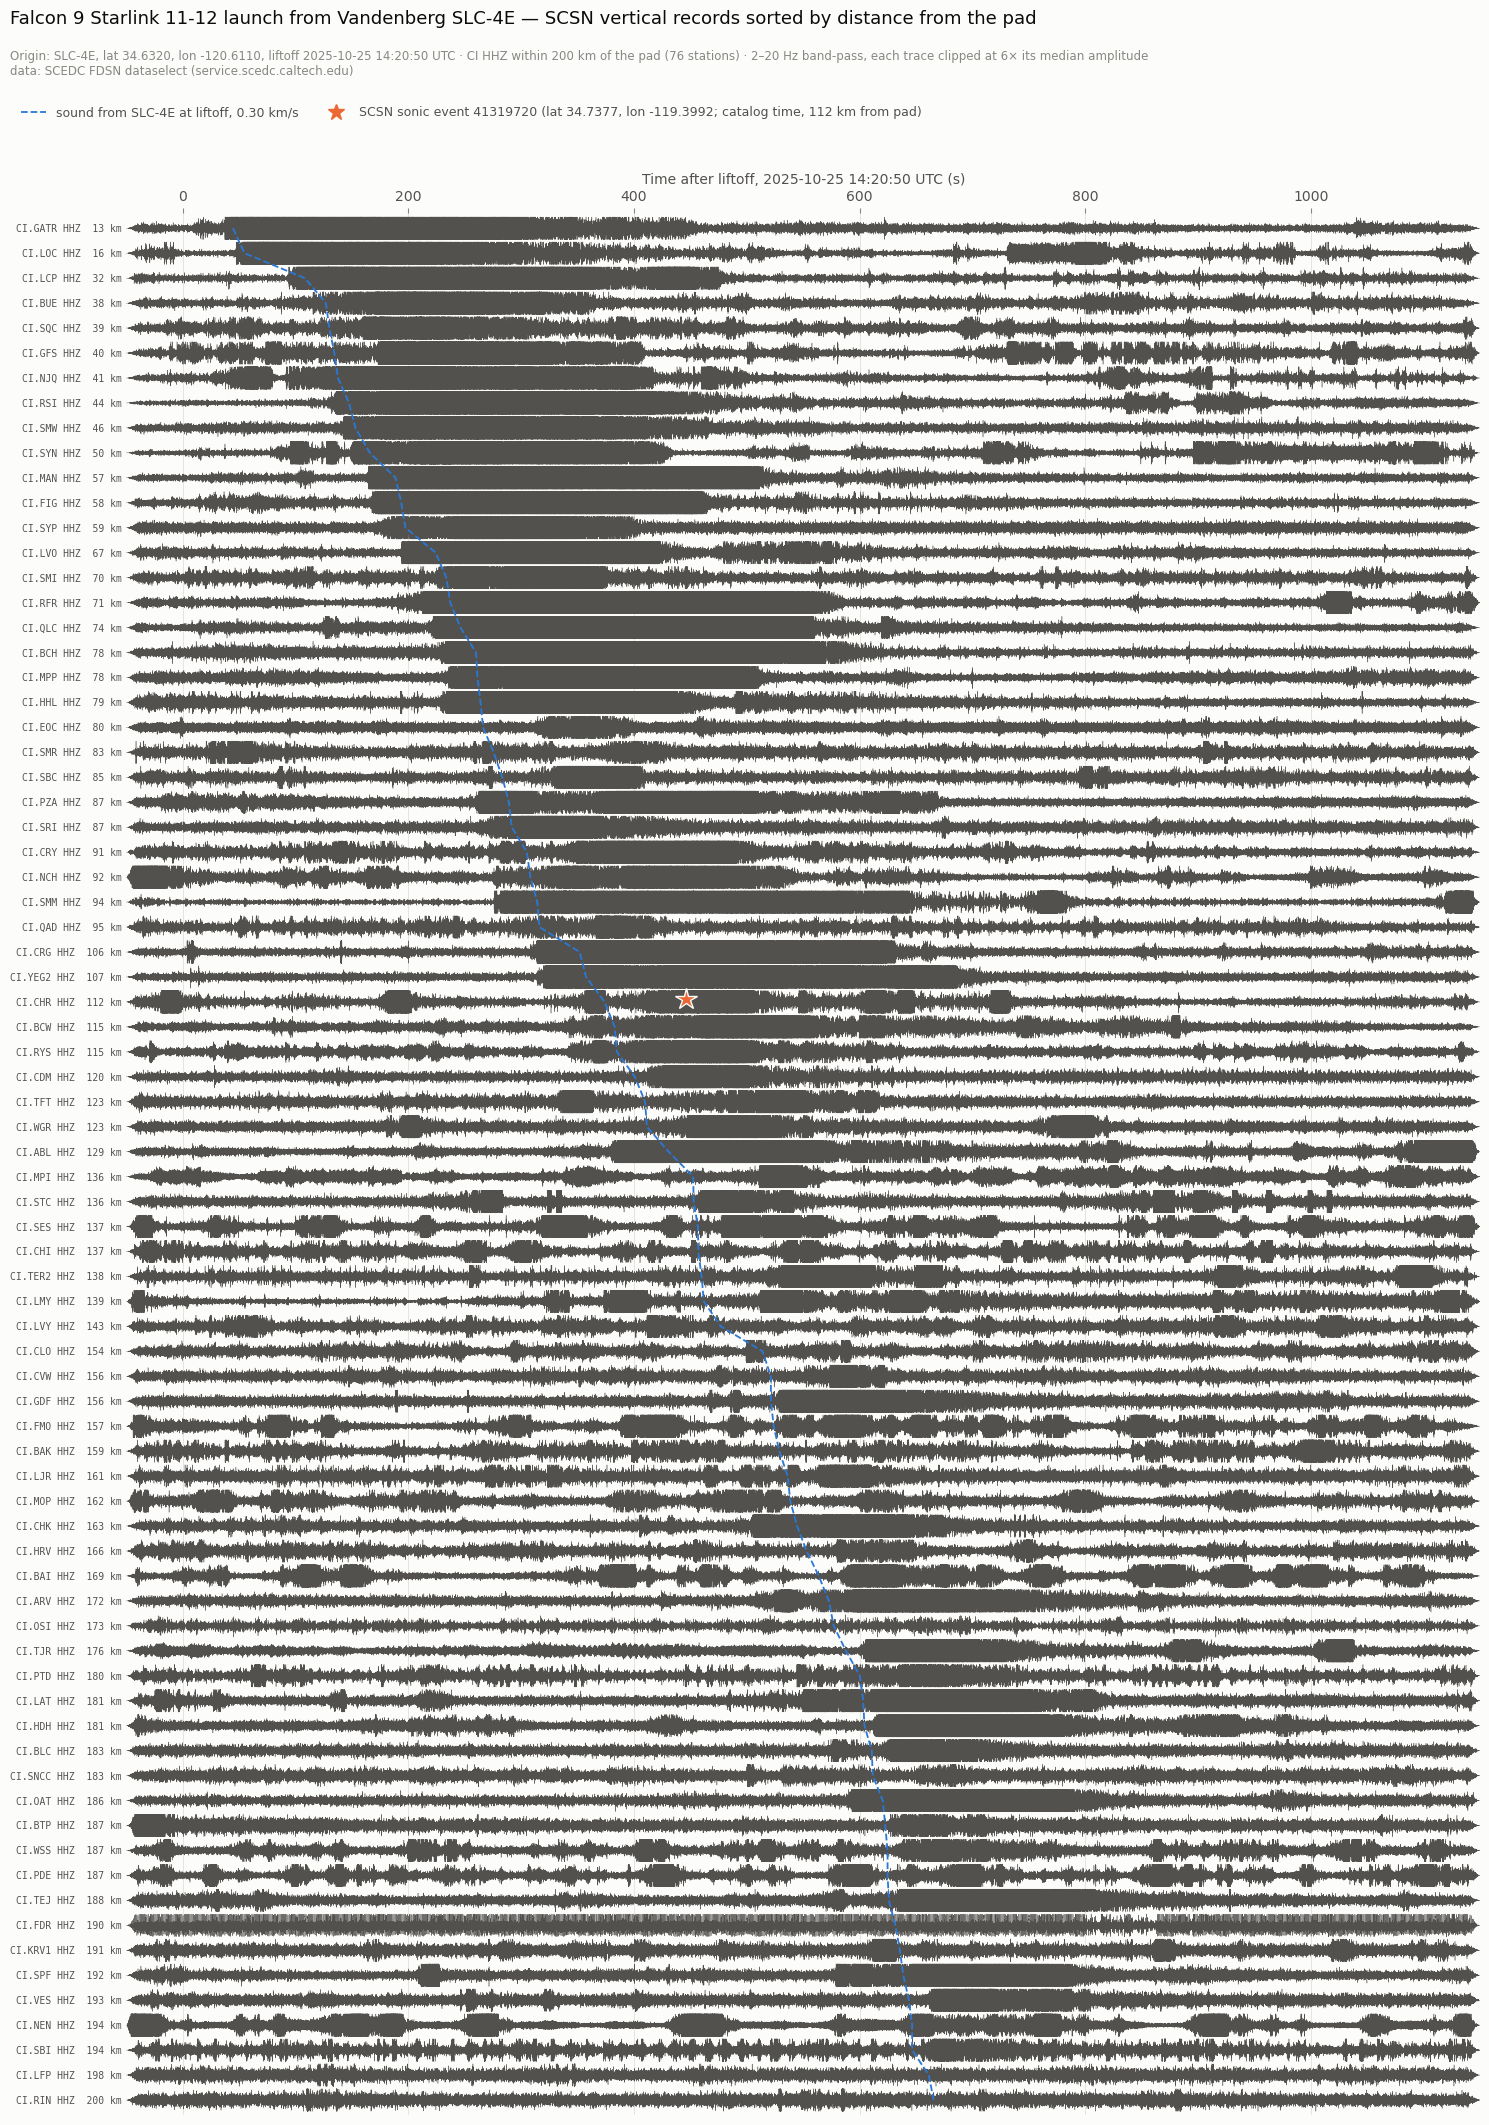

sonic event is 111.7 km from pad, 446.4 s after liftoff -> 0.250 km/s


In [10]:
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
TRACE, CEL_COLOR, EV_COLOR = "#52514e", "#2a78d6", "#eb6834"   # gray, blue, orange

fig, ax = plt.subplots(figsize=(15, 0.25 * len(rows) + 2.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for i, r in enumerate(rows):
    tr = r["tr"].copy()
    tr.detrend("demean"); tr.detrend("linear"); tr.taper(0.01)
    tr.filter("bandpass", freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=True)
    # tr.times() is seconds after the trace start; shift it so every row
    # shares the same time axis, seconds after liftoff.
    t = tr.times() + (tr.stats.starttime - LAUNCH)
    y = tr.data.astype(float)
    scale = 6 * np.median(np.abs(y)) or 1.0
    y = np.clip(y / scale, -1, 1) * 0.45
    # Rows count downward, so subtract to keep positive motion pointing up.
    ax.plot(t, i - y, color=TRACE, lw=0.3, zorder=2)

# Sound-front line: a station at distance d hears it d / CELERITY seconds
# after liftoff.
d = np.array([r["dist"] for r in rows])
yy = np.arange(len(rows))
ax.plot(d / CELERITY, yy, color=CEL_COLOR, lw=1.3, ls="--", zorder=3)
# Place the star between the rows of the stations nearest its distance.
iev = np.interp(ev_dist, d, yy)
ax.plot(EVENT["t"] - LAUNCH, iev, marker="*", ms=16, color=EV_COLOR, mec=SURFACE, zorder=5)

ax.set_yticks(yy)
ax.set_yticklabels([f"CI.{r['sta']} HHZ  {r['dist']:.0f} km" for r in rows],
                   fontsize=7, color=INK2, family="monospace")
ax.set_ylim(len(rows) - 0.4, -0.6)
ax.set_xlim(-50, 1150)
ax.set_xlabel("Time after liftoff, 2025-10-25 14:20:50 UTC (s)", color=INK2, fontsize=10)
ax.xaxis.set_label_position("top"); ax.xaxis.tick_top()
ax.grid(True, axis="x", color=GRID, lw=0.6)
ax.set_axisbelow(True)
for side in ax.spines:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="x", colors=MUTED, labelcolor=INK2)
ax.tick_params(axis="y", length=0)

# Put the title and legend above the axes so they never cover a trace.
H = fig.get_figheight()
handles = [Line2D([], [], color=CEL_COLOR, lw=1.3, ls="--"),
           Line2D([], [], ls="", marker="*", ms=12, color=EV_COLOR)]
labels = [f"sound from SLC-4E at liftoff, {CELERITY:.2f} km/s",
          f"SCSN sonic event 41319720 (lat {EVENT['lat']:.4f}, lon {EVENT['lon']:.4f}; "
          f"catalog time, {ev_dist:.0f} km from pad)"]
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 1 - 1.05 / H), ncol=4,
           frameon=False, labelcolor=INK2, fontsize=9)
fig.suptitle("Falcon 9 Starlink 11-12 launch from Vandenberg SLC-4E — SCSN vertical records sorted by distance from the pad",
             x=0.01, y=1 - 0.2 / H, ha="left", va="top", color=INK, fontsize=13)
liftoff = str(LAUNCH)[:19].replace("T", " ")
fig.text(0.01, 1 - 0.6 / H, va="top", color=MUTED, fontsize=8.5,
         s=f"Origin: SLC-4E, lat {PAD[0]:.4f}, lon {PAD[1]:.4f}, liftoff {liftoff} UTC · "
           f"CI HHZ within 200 km of the pad ({len(rows)} stations) · "
           f"{BAND[0]:.0f}–{BAND[1]:.0f} Hz band-pass, each trace clipped at 6× its median amplitude\n"
           "data: SCEDC FDSN dataselect (service.scedc.caltech.edu)")
fig.tight_layout(rect=(0, 0, 1, 1 - 1.35 / H))   # leave room for the title and legend
plt.show()

dt = EVENT["t"] - LAUNCH
print(f"sonic event is {ev_dist:.1f} km from pad, {dt:.1f} s after liftoff -> {ev_dist / dt:.3f} km/s")